# Cut & Paste 합성 결함 미리보기

MVTec `screw` 의 **train 실제 결함(마스크 기반)** 을 **정상 train 이미지**의 같은 해부학적 위치에 이식하고(Poisson blending), 결과를 눈으로 확인하는 노트북.
파일은 저장하지 않고 화면에만 그린다(생성 파이프라인 확정 전 점검용).

- 소스는 `baseline_split.csv` 의 **train** 결함만 사용 — **test 결함은 합성에 쓰지 않는다**(평가 누수 방지).
- 위치 정합: 전경 분할 → PCA 주축으로 머리~끝 좌표 `t`(0=머리, 1=끝), 폭 방향 좌표 `s`(-1~1)를 구해 소스 결함의 (t, s) 를 대상 나사의 같은 (t, s) 로 옮긴다.
- 실행 환경: conda `screw_defect`, 이 폴더(`experiments/supervised`)에서 실행.

In [1]:
import os, sys, math
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
from pathlib import Path
import functools
import numpy as np
import cv2
import matplotlib.pyplot as plt

# 레포 루트 탐색 (노트북 cwd 와 무관하게 동작)
ROOT = Path.cwd().resolve()
while not (ROOT / "src").is_dir() or not (ROOT / "splits").is_dir():
    if ROOT.parent == ROOT:
        raise RuntimeError("레포 루트를 찾지 못함")
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src.common.paths import MVTEC_DIR
from src.supervised.data import list_records

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False
print("ROOT:", ROOT)
print("cv2:", cv2.__version__)

ROOT: C:\Users\한국전파진흥협회\OneDrive\Desktop\project\screw-defect-mes
cv2: 5.0.0


## 1. 설정 (확정 시 `synth_config.py` 로 이동할 값)

In [2]:
SEED = 42
SYNTH_RATIO = 0.25        # 정상 train 대비 합성 결함 비율 (0.20~0.30 권장)
TYPES = ["type1", "type2", "type3", "type4", "type5"]
TYPE_FOLDER = {"type1": "manipulated_front", "type2": "scratch_head", "type3": "scratch_neck",
               "type4": "thread_side", "type5": "thread_top"}

T_TOL = 0.04              # 소스 결함 t 위치 허용 오차(축 방향, 0~1 정규화)
S_TOL = 0.15              # 폭 방향 s 허용 오차
ROT_JITTER = 10           # 회전 지터(도)
SCALE_RANGE = (0.85, 1.15)
PAD = 14                  # 결함 bbox 주변 여유(px) — Poisson 이 주변 맥락을 쓰도록
DILATE = 5                # 클론 영역 = 결함 마스크를 이만큼 팽창
LARGEST_ONLY = True       # GT 마스크가 여러 조각이면 가장 큰 조각만 이식(조각 사이 정상 영역까지 복제되는 것 방지)
CLONE_MODE = "normal"     # 'normal' | 'mixed' | 'naive'(그냥 덮어쓰기: 비교용)
MIN_FG_FRAC = 0.9         # 합성 마스크가 "나사 몸체 근방" 안에 있어야 하는 최소 비율
NEAR_PX = 31              # 몸체 근방 = 전경을 이만큼 팽창(manipulated_front 는 끝이 결손돼 마스크가 몸체 밖으로 나감)
CORE_DROP = 90            # 배경 밝기보다 이만큼 이상 어두운 픽셀만 "나사 몸체"로 인정(그림자 제외)

## 2. 데이터 — train 결함(소스 후보)·train 정상(대상 후보)과 유형별 수량 집계

In [3]:
src_by_type = {t: list_records("train", [t]) for t in TYPES}
good_train = list_records("train", ["good"])
good_test_ids = {r["path"] for r in list_records("test", ["good"])}
assert not ({r["path"] for r in good_train} & good_test_ids)

N_GOOD = len(good_train)
TOTAL = round(N_GOOD * SYNTH_RATIO)
# 유형 균등 배분 (현재 보유 수량이 적은 유형부터 채움)
have = {t: len(v) for t, v in src_by_type.items()}
add = {t: 0 for t in TYPES}
for _ in range(TOTAL):
    t = min(TYPES, key=lambda k: have[k] + add[k])
    add[t] += 1

print(f"정상 train {N_GOOD}장 × {SYNTH_RATIO} = 합성 {TOTAL}장\n")
print(f"{'유형':<7}{'폴더':<20}{'real train':>11}{'합성 추가':>10}{'합계':>6}")
for t in TYPES:
    print(f"{t:<7}{TYPE_FOLDER[t]:<20}{have[t]:>11}{add[t]:>10}{have[t]+add[t]:>6}")

정상 train 325장 × 0.25 = 합성 81장

유형     폴더                   real train     합성 추가    합계
type1  manipulated_front            20        17    37
type2  scratch_head                 20        16    36
type3  scratch_neck                 20        16    36
type4  thread_side                  20        16    36
type5  thread_top                   20        16    36


## 3. 전경 분할 + PCA 주축 좌표계

나사는 이미지마다 회전돼 있어서, 나사 자체에 붙은 좌표 `(t, s)` 로 위치를 표현한다.
머리 방향은 **폭이 더 넓은 쪽**으로 정한다.

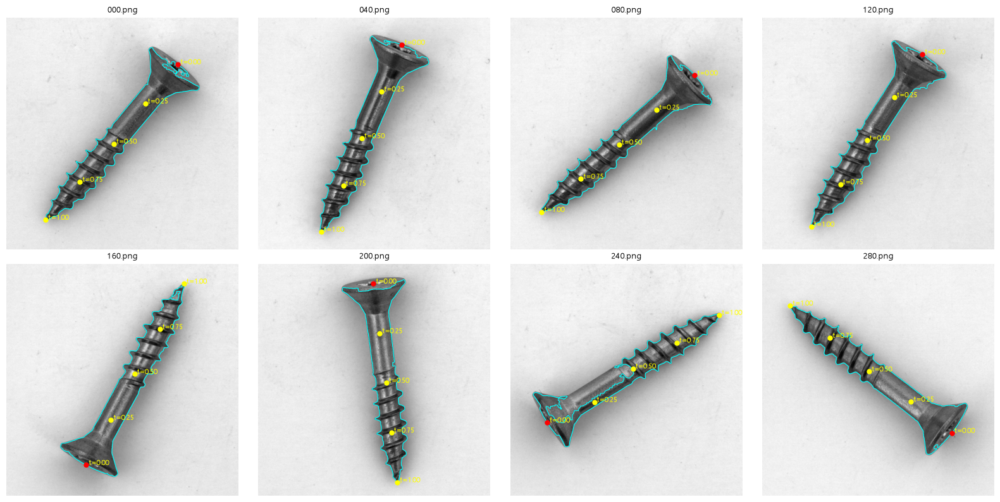

In [4]:
def read_gray(path):
    # cv2.imread 는 한글 경로를 못 읽으므로 fromfile+imdecode 사용
    img = cv2.imdecode(np.fromfile(path, np.uint8), cv2.IMREAD_GRAYSCALE)
    assert img is not None, path
    return img

def foreground_mask(gray):
    blur = cv2.GaussianBlur(gray, (0, 0), 3)
    _, bw = cv2.threshold(blur, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    if bw.mean() / 255 > 0.5:          # 전경이 소수 면적이 되도록 극성 정렬
        bw = 255 - bw
    bw = cv2.morphologyEx(bw, cv2.MORPH_CLOSE, np.ones((15, 15), np.uint8))
    n, lab, stats, _ = cv2.connectedComponentsWithStats(bw)
    if n <= 1:
        return np.zeros_like(bw)
    k = 1 + int(np.argmax(stats[1:, cv2.CC_STAT_AREA]))
    comp = (lab == k).astype(np.uint8) * 255
    cnts, _ = cv2.findContours(comp, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    filled = np.zeros_like(comp)
    cv2.drawContours(filled, cnts, -1, 255, -1)
    return filled

NBINS = 40
TC = (np.arange(NBINS) + 0.5) / NBINS

def _profile(P, c, v):
    n = np.array([-v[1], v[0]], dtype=np.float32)
    a = (P - c) @ v
    b = (P - c) @ n
    tmin, tmax = float(a.min()), float(a.max())
    idx = np.clip(((a - tmin) / (tmax - tmin) * NBINS).astype(int), 0, NBINS - 1)
    lo = np.full(NBINS, np.nan); hi = np.full(NBINS, np.nan)
    for k in range(NBINS):
        sel = idx == k
        if sel.any():
            lo[k], hi[k] = b[sel].min(), b[sel].max()
    ok = ~np.isnan(lo)
    lo = np.interp(TC, TC[ok], lo[ok]); hi = np.interp(TC, TC[ok], hi[ok])
    return n, tmin, tmax, lo, hi

def screw_axis(fg):
    ys, xs = np.nonzero(fg)
    P = np.stack([xs, ys], 1).astype(np.float32)
    c = P.mean(0)
    _, V = np.linalg.eigh(np.cov((P - c).T))
    v = V[:, 1].astype(np.float32)
    n, tmin, tmax, lo, hi = _profile(P, c, v)
    w = hi - lo
    q = NBINS // 4
    if w[-q:].mean() > w[:q].mean():   # 머리(폭이 넓은 쪽)가 t=0 이 되도록 뒤집기
        v = -v
        n, tmin, tmax, lo, hi = _profile(P, c, v)
    return dict(c=c, v=v, n=n, tmin=tmin, tmax=tmax, mid=(lo + hi) / 2, width=hi - lo,
                theta=math.degrees(math.atan2(v[1], v[0])))

def to_ts(ax, pt):
    d = np.asarray(pt, np.float32) - ax["c"]
    t = (float(d @ ax["v"]) - ax["tmin"]) / (ax["tmax"] - ax["tmin"])
    mid = np.interp(t, TC, ax["mid"]); w = np.interp(t, TC, ax["width"])
    return t, (float(d @ ax["n"]) - mid) / (w / 2 + 1e-6)

def from_ts(ax, t, s):
    mid = np.interp(t, TC, ax["mid"]); w = np.interp(t, TC, ax["width"])
    a = ax["tmin"] + t * (ax["tmax"] - ax["tmin"])
    return ax["c"] + a * ax["v"] + (mid + s * w / 2) * ax["n"]

def tight_foreground(g, fg):
    # Otsu 전경은 그림자까지 포함 → 배경보다 확실히 어두운 픽셀만 남겨 실제 나사 몸체로 정제
    bg = np.median(g[fg == 0])
    c = ((cv2.GaussianBlur(g, (0, 0), 2) < bg - CORE_DROP) & (fg > 0)).astype(np.uint8) * 255
    c = cv2.morphologyEx(c, cv2.MORPH_CLOSE, np.ones((9, 9), np.uint8))
    n, lab, st, _ = cv2.connectedComponentsWithStats(c)
    if n <= 1:
        return fg
    k = 1 + int(np.argmax(st[1:, cv2.CC_STAT_AREA]))
    c = (lab == k).astype(np.uint8) * 255
    cn, _ = cv2.findContours(c, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    f = np.zeros_like(c)
    cv2.drawContours(f, cn, -1, 255, -1)   # 밝은 반사로 생긴 내부 구멍 메움
    return f

@functools.lru_cache(maxsize=512)
def analyze(path):
    g = read_gray(path)
    fg = tight_foreground(g, foreground_mask(g))
    return g, fg, screw_axis(fg)

def show_axis(ax_, path, title=""):
    g, fg, a = analyze(path)
    ax_.imshow(g, cmap="gray"); ax_.contour(fg > 0, levels=[0.5], colors="cyan", linewidths=0.8)
    for t in (0, 0.25, 0.5, 0.75, 1.0):
        p = from_ts(a, t, 0.0)
        ax_.plot(*p, "o", ms=5, color="red" if t == 0 else "yellow")
        ax_.text(p[0] + 12, p[1], f"t={t:.2f}", color="yellow", fontsize=8)
    ax_.set_title(title or os.path.basename(path), fontsize=9); ax_.axis("off")

# 전경·축 점검: 정상 8장 (빨간 점 = 머리 쪽 t=0)
fig, axs = plt.subplots(2, 4, figsize=(16, 8))
for a_, r in zip(axs.ravel(), good_train[::40][:8]):
    show_axis(a_, r["path"], r["filename"])
plt.tight_layout(); plt.show()

## 4. 결함 patch 추출 → 회전·스케일 → Poisson blending

In [5]:
def largest_component(m):
    n, lab, st, _ = cv2.connectedComponentsWithStats(m.astype(np.uint8))
    if n <= 2:
        return m
    return lab == 1 + int(np.argmax(st[1:, cv2.CC_STAT_AREA]))

def extract_patch(gray, mask):
    m = mask > 127
    if LARGEST_ONLY:
        m = largest_component(m)
    ys, xs = np.nonzero(m)
    x0, x1 = max(xs.min() - PAD, 0), min(xs.max() + PAD + 1, gray.shape[1])
    y0, y1 = max(ys.min() - PAD, 0), min(ys.max() + PAD + 1, gray.shape[0])
    mm = (m[y0:y1, x0:x1].astype(np.uint8)) * 255
    clone = cv2.dilate(mm, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * DILATE + 1,) * 2))
    return dict(img=gray[y0:y1, x0:x1].copy(), mask=mm, clone=clone,
                centroid=np.array([xs.mean() - x0, ys.mean() - y0], np.float32))

def transform_patch(p, angle, scale):
    h, w = p["img"].shape
    M = cv2.getRotationMatrix2D((w / 2, h / 2), angle, scale)
    cs, sn = abs(M[0, 0]), abs(M[0, 1])
    nw, nh = int(h * sn + w * cs) + 2, int(h * cs + w * sn) + 2
    M[0, 2] += nw / 2 - w / 2; M[1, 2] += nh / 2 - h / 2
    img = cv2.warpAffine(p["img"], M, (nw, nh), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REPLICATE)
    mask = cv2.warpAffine(p["mask"], M, (nw, nh), flags=cv2.INTER_LINEAR) > 127
    clone = cv2.warpAffine(p["clone"], M, (nw, nh), flags=cv2.INTER_LINEAR) > 127
    cen = M @ np.array([*p["centroid"], 1.0])
    # 클론 영역 bbox 로 자르되 크기를 홀수로 맞춰 seamlessClone 중심을 정확히 지정
    ys, xs = np.nonzero(clone)
    x0, x1, y0, y1 = max(xs.min() - 2, 0), min(xs.max() + 3, nw), max(ys.min() - 2, 0), min(ys.max() + 3, nh)
    if (x1 - x0) % 2 == 0: x1 = x1 + 1 if x1 < nw else x1 - 1
    if (y1 - y0) % 2 == 0: y1 = y1 + 1 if y1 < nh else y1 - 1
    sl = (slice(y0, y1), slice(x0, x1))
    return dict(img=img[sl], mask=(mask[sl] * 255).astype(np.uint8), clone=(clone[sl] * 255).astype(np.uint8),
                centroid=(cen - [x0, y0]).astype(np.float32))

def paste(dst_gray, tp, target_pt, mode):
    # 반환: (합성 이미지, 합성 GT 마스크) 또는 (None, None)
    h, w = tp["img"].shape
    H, W = dst_gray.shape
    center = np.round(np.asarray(target_pt) - (tp["centroid"] - [w // 2, h // 2])).astype(int)
    x0, y0 = center[0] - w // 2, center[1] - h // 2
    if x0 < 1 or y0 < 1 or x0 + w > W - 1 or y0 + h > H - 1:
        return None, None
    if mode == "naive":
        out = dst_gray.copy()
        roi = out[y0:y0 + h, x0:x0 + w]
        roi[tp["clone"] > 0] = tp["img"][tp["clone"] > 0]
    else:
        flag = cv2.NORMAL_CLONE if mode == "normal" else cv2.MIXED_CLONE
        src3 = cv2.cvtColor(tp["img"], cv2.COLOR_GRAY2BGR)
        dst3 = cv2.cvtColor(dst_gray, cv2.COLOR_GRAY2BGR)
        out = cv2.cvtColor(cv2.seamlessClone(src3, dst3, tp["clone"], (int(center[0]), int(center[1])), flag),
                           cv2.COLOR_BGR2GRAY)
    gt = np.zeros((H, W), np.uint8)
    gt[y0:y0 + h, x0:x0 + w] = tp["mask"]
    return out, gt

def generate_one(src_rec, good_rec, seed, mode=None, tries=30):
    mode = mode or CLONE_MODE
    rng = np.random.default_rng(seed)
    sg, _, sax = analyze(src_rec["path"])
    mask = read_gray(src_rec["mask"])
    patch = extract_patch(sg, mask)
    mm = largest_component(mask > 127) if LARGEST_ONLY else (mask > 127)
    ys, xs = np.nonzero(mm)
    t0, s0 = to_ts(sax, (xs.mean(), ys.mean()))
    gg, gfg, gax = analyze(good_rec["path"])
    near = cv2.dilate(gfg, np.ones((NEAR_PX, NEAR_PX), np.uint8))   # gfg: 이미 나사 몸체(그림자 제외)
    for _ in range(tries):
        t = float(np.clip(t0 + rng.uniform(-T_TOL, T_TOL), 0.02, 0.98))
        s = float(np.clip(s0 + rng.uniform(-S_TOL, S_TOL), -0.9, 0.9))
        angle = (sax["theta"] - gax["theta"]) + rng.uniform(-ROT_JITTER, ROT_JITTER)
        scale = rng.uniform(*SCALE_RANGE)
        pt = from_ts(gax, t, s)
        tp = transform_patch(patch, angle, scale)
        out, gt = paste(gg, tp, pt, mode)
        if out is None:
            continue
        if gfg[int(round(pt[1])), int(round(pt[0]))] == 0:      # 이식 중심은 반드시 몸체 위
            continue
        if (near[gt > 0] > 0).mean() < MIN_FG_FRAC:
            continue
        return dict(img=out, mask=gt, src=src_rec, good=good_rec, t=t, s=s, t_src=t0, s_src=s0,
                    angle=angle, scale=scale, patch=patch, tpatch=tp, pt=pt)
    return None

## 5. 파이프라인 한 건 단계별 확인

소스(결함+마스크) → 소스의 (t,s) → 대상 정상 나사의 같은 (t,s) → 합성.

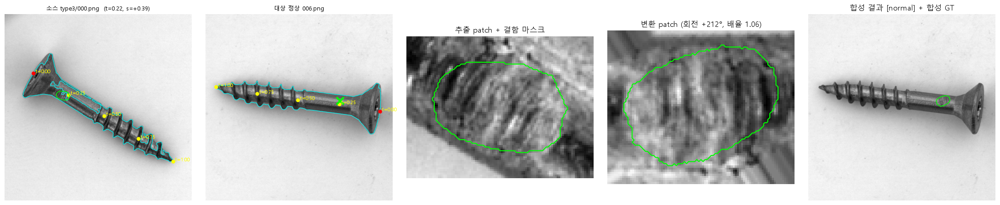

In [6]:
def zoom(img, pt, half=110):
    x, y = int(pt[0]), int(pt[1])
    x0, y0 = np.clip(x - half, 0, img.shape[1] - 2 * half), np.clip(y - half, 0, img.shape[0] - 2 * half)
    return (slice(y0, y0 + 2 * half), slice(x0, x0 + 2 * half)), (x0, y0)

def show_pipeline(type_key, src_idx=0, good_idx=0, seed=SEED, mode=None):
    s = src_by_type[type_key][src_idx]
    for gi in range(good_idx, good_idx + 50):        # 실패하면 다음 정상 이미지로
        g = good_train[gi % len(good_train)]
        r = generate_one(s, g, seed, mode)
        if r is not None:
            break
    else:
        print("생성 실패"); return
    sg, _, _ = analyze(s["path"])
    smask = read_gray(s["mask"]) > 127
    fig, axs = plt.subplots(1, 5, figsize=(22, 4.8))
    show_axis(axs[0], s["path"], f"소스 {type_key}/{s['filename']}  (t={r['t_src']:.2f}, s={r['s_src']:+.2f})")
    axs[0].contour(smask, levels=[0.5], colors="lime", linewidths=1)
    show_axis(axs[1], g["path"], f"대상 정상 {g['filename']}")
    axs[1].plot(*r["pt"], "x", color="lime", ms=12, mew=3)
    axs[2].imshow(r["patch"]["img"], cmap="gray"); axs[2].contour(r["patch"]["mask"] > 0, levels=[0.5], colors="lime")
    axs[2].set_title("추출 patch + 결함 마스크"); axs[2].axis("off")
    tp = r["tpatch"]
    axs[3].imshow(tp["img"], cmap="gray"); axs[3].contour(tp["mask"] > 0, levels=[0.5], colors="lime")
    axs[3].set_title(f"변환 patch (회전 {r['angle']:+.0f}°, 배율 {r['scale']:.2f})"); axs[3].axis("off")
    axs[4].imshow(r["img"], cmap="gray"); axs[4].contour(r["mask"] > 0, levels=[0.5], colors="lime", linewidths=1)
    axs[4].set_title(f"합성 결과 [{mode or CLONE_MODE}] + 합성 GT"); axs[4].axis("off")
    plt.tight_layout(); plt.show()

show_pipeline("type3", src_idx=0, good_idx=5)

## 6. 유형별 합성 샘플

행 = 합성 한 건. 열: 소스(결함 윤곽) / 대상 정상 / 합성(GT 윤곽) / 소스 확대 / 합성 확대 / |합성-정상| 확대(무엇이 바뀌었나).

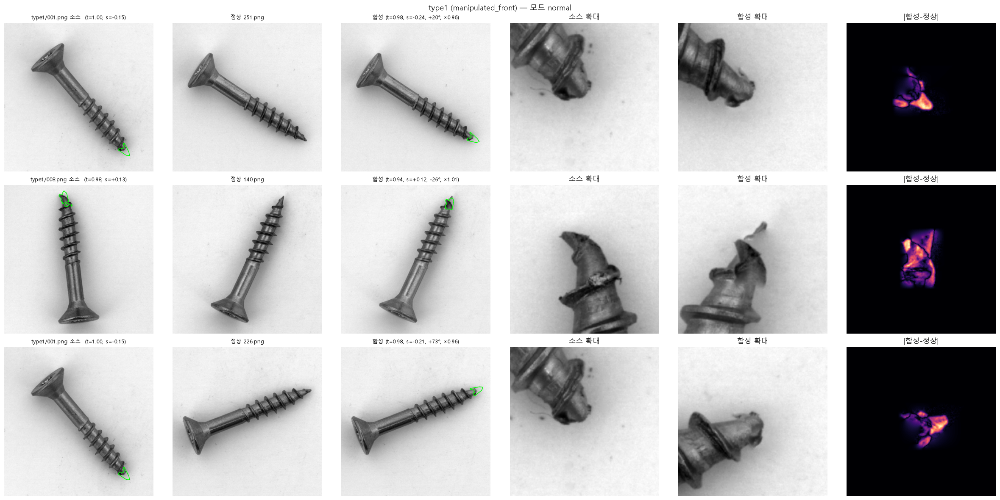

In [7]:
def show_type(type_key, n=3, seed=SEED, mode=None):
    rng = np.random.default_rng(seed)
    fig, axs = plt.subplots(n, 6, figsize=(24, 4 * n))
    axs = np.atleast_2d(axs)
    row = 0
    while row < n:
        s = src_by_type[type_key][rng.integers(len(src_by_type[type_key]))]
        g = good_train[rng.integers(len(good_train))]
        r = generate_one(s, g, int(rng.integers(1 << 30)), mode)
        if r is None:
            continue
        sg, _, _ = analyze(s["path"]); smask = read_gray(s["mask"]) > 127
        ys, xs = np.nonzero(largest_component(smask) if LARGEST_ONLY else smask); sc = (xs.mean(), ys.mean())
        ys2, xs2 = np.nonzero(r["mask"] > 0); dc = (xs2.mean(), ys2.mean())
        sl_s, _ = zoom(sg, sc); sl_d, _ = zoom(r["img"], dc)
        a = axs[row]
        a[0].imshow(sg, cmap="gray"); a[0].contour(smask, levels=[0.5], colors="lime", linewidths=1)
        a[0].set_title(f"{type_key}/{s['filename']} 소스  (t={r['t_src']:.2f}, s={r['s_src']:+.2f})", fontsize=9)
        a[1].imshow(analyze(g["path"])[0], cmap="gray"); a[1].set_title(f"정상 {g['filename']}", fontsize=9)
        a[2].imshow(r["img"], cmap="gray"); a[2].contour(r["mask"] > 0, levels=[0.5], colors="lime", linewidths=1)
        a[2].set_title(f"합성 (t={r['t']:.2f}, s={r['s']:+.2f}, {r['angle']:+.0f}°, ×{r['scale']:.2f})", fontsize=9)
        a[3].imshow(sg[sl_s], cmap="gray"); a[3].set_title("소스 확대")
        a[4].imshow(r["img"][sl_d], cmap="gray"); a[4].set_title("합성 확대")
        diff = cv2.absdiff(r["img"], analyze(g["path"])[0])
        a[5].imshow(diff[sl_d], cmap="magma", vmin=0, vmax=max(int(diff.max()), 1)); a[5].set_title("|합성-정상|")
        for x in a: x.axis("off")
        row += 1
    fig.suptitle(f"{type_key} ({TYPE_FOLDER[type_key]}) — 모드 {mode or CLONE_MODE}", fontsize=13)
    plt.tight_layout(); plt.show()

show_type("type1", n=3)

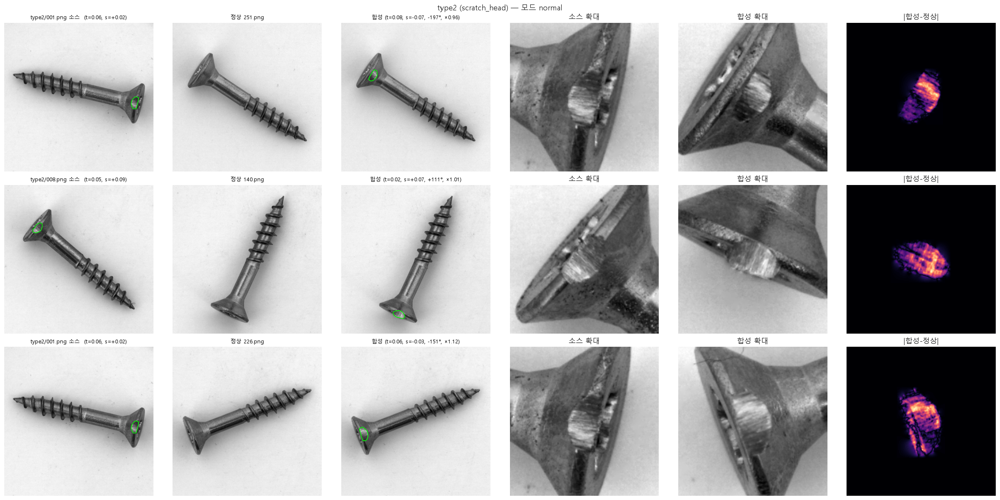

In [8]:
show_type("type2", n=3)

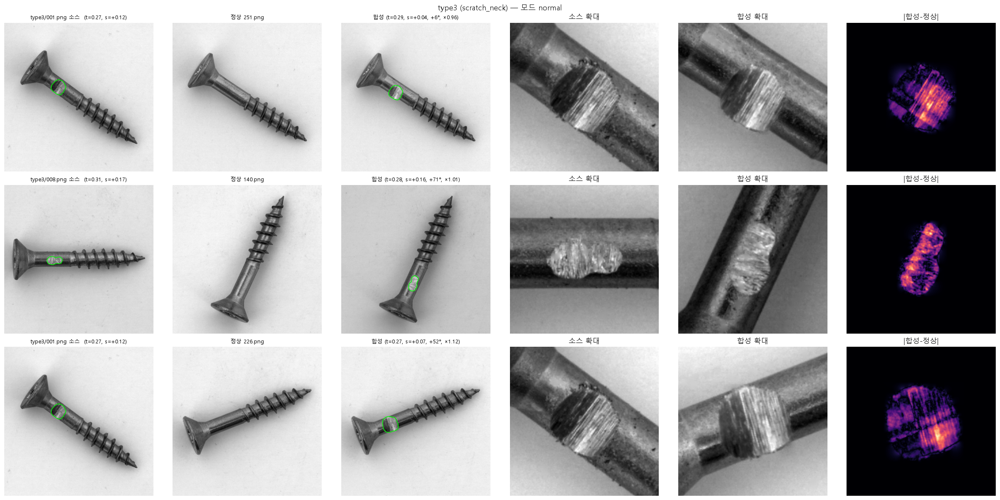

In [9]:
show_type("type3", n=3)

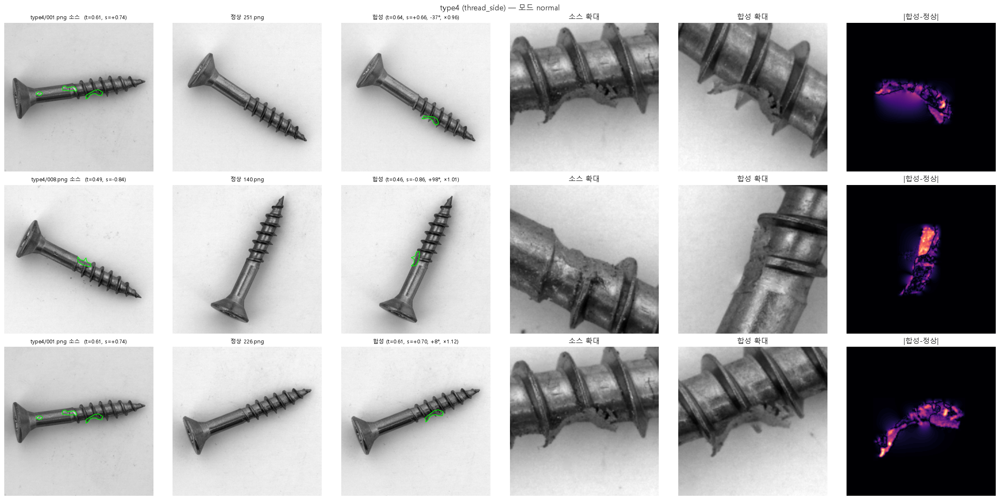

In [10]:
show_type("type4", n=3)

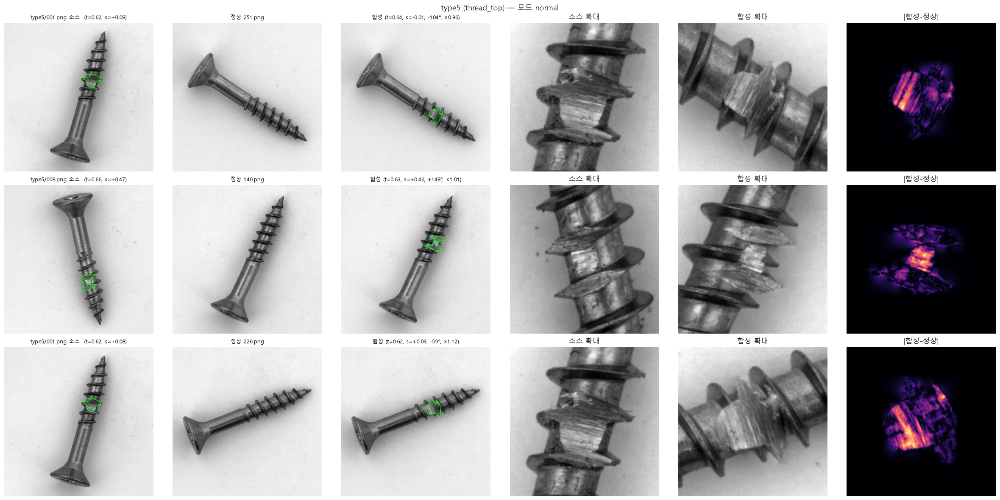

In [11]:
show_type("type5", n=3)

## 7. 블렌딩 방식 비교 — 단순 덮어쓰기 vs `NORMAL_CLONE` vs `MIXED_CLONE`

같은 소스·대상·위치(같은 seed)에서 방식만 바꾼다. 경계 이음선이 남는지, 가는 스크래치 대비가 지워지지 않는지 확인.

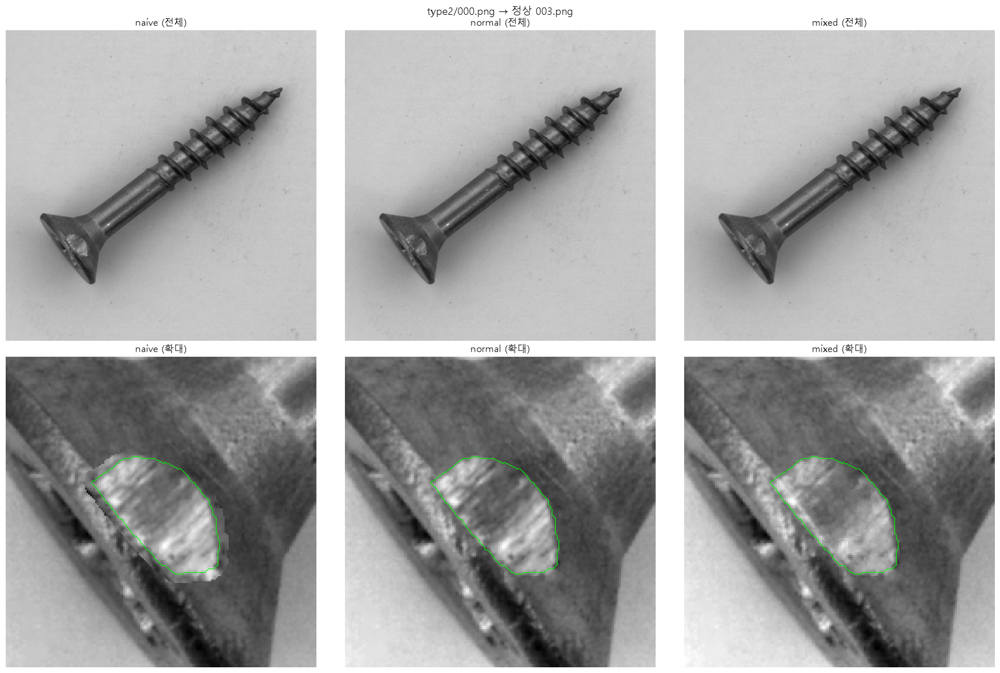

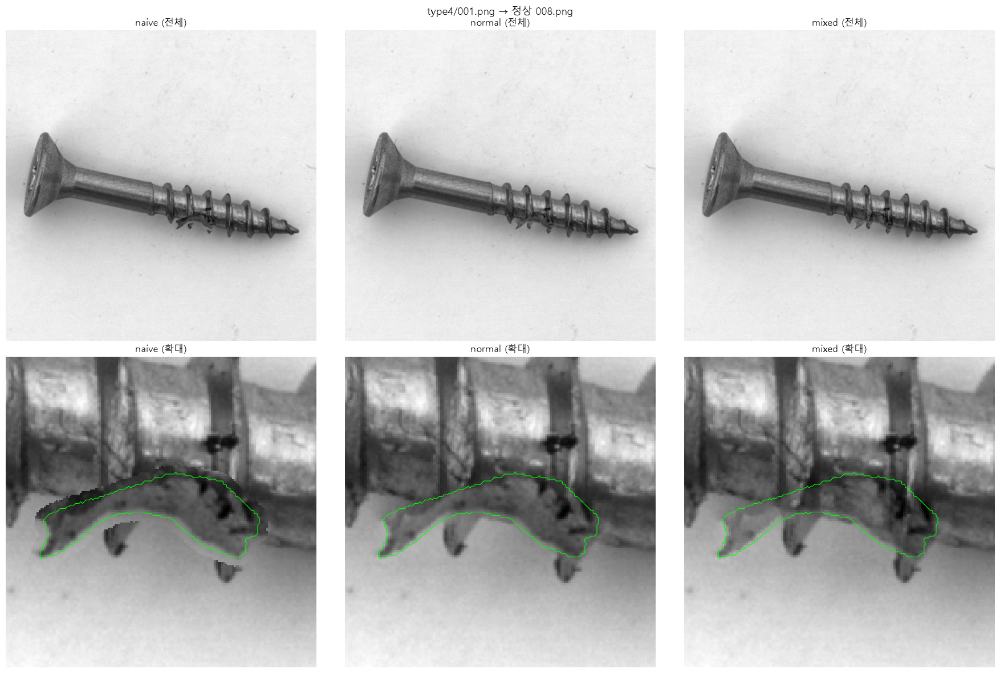

In [12]:
def compare_modes(type_key, src_idx=0, good_idx=3, seed=SEED):
    s = src_by_type[type_key][src_idx]; g = good_train[good_idx]
    fig, axs = plt.subplots(2, 3, figsize=(18, 12))
    for j, mode in enumerate(["naive", "normal", "mixed"]):
        r = generate_one(s, g, seed, mode)
        if r is None:
            axs[0, j].set_title(f"{mode}: 생성 실패"); continue
        ys, xs = np.nonzero(r["mask"] > 0)
        sl, _ = zoom(r["img"], (xs.mean(), ys.mean()), half=90)
        axs[0, j].imshow(r["img"], cmap="gray"); axs[0, j].set_title(f"{mode} (전체)")
        axs[1, j].imshow(r["img"][sl], cmap="gray"); axs[1, j].set_title(f"{mode} (확대)")
        axs[1, j].contour(r["mask"][sl] > 0, levels=[0.5], colors="lime", linewidths=0.8)
    for x in axs.ravel(): x.axis("off")
    fig.suptitle(f"{type_key}/{s['filename']} → 정상 {g['filename']}", fontsize=13)
    plt.tight_layout(); plt.show()

compare_modes("type2", src_idx=0, good_idx=3)
compare_modes("type4", src_idx=1, good_idx=8)

## 8. 생성 성공률 점검

전경 밖/경계 초과로 `None` 이 나오는 비율. 높으면 `T_TOL`·`S_TOL`·`MIN_FG_FRAC` 를 조정한다.

In [13]:
rng = np.random.default_rng(SEED)
print(f"{'유형':<7}{'시도':>5}{'성공':>5}{'성공률':>8}")
for t in TYPES:
    ok = 0; N = 20
    for _ in range(N):
        s = src_by_type[t][rng.integers(len(src_by_type[t]))]
        g = good_train[rng.integers(len(good_train))]
        ok += generate_one(s, g, int(rng.integers(1 << 30))) is not None
    print(f"{t:<7}{N:>5}{ok:>5}{ok/N:>8.0%}")

유형        시도   성공     성공률
type1     20   20    100%
type2     20   20    100%
type3     20   17     85%
type4     20   19     95%
type5     20   18     90%
